# 01 · The FrozenLake environment

**In this notebook**
- The two maps we use (4x4 and 8x8), and what each square means.
- The **rewards** the agent gets, and why we changed the default ones.
- Why the ice is **not slippery** in our tests.
- A check that all three methods get exactly the same rewards.

Nothing is learned here. This notebook just explains the setup for notebooks 02–05.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from frozenlake_rl.config import CONFIG
from frozenlake_rl import env as fl, plotting as plot
from frozenlake_rl.experiments import load_vi, load_td, q_table
from frozenlake_rl.evaluate import greedy_policy, mean_and_ci, seeds_on_time_grid

plot.apply_style()
pd.set_option("display.precision", 3)
MAPS = list(CONFIG["maps"])          # ["4x4", "8x8"]
RERUN = False                        # True = ignore cached CSVs in results/ and recompute

## The task

An agent stands on a frozen lake. The lake is a grid of squares. Each square is one of these:

| Letter | Meaning |
|---|---|
| **S** | Start: every attempt begins here |
| **F** | Frozen ice: safe to stand on |
| **H** | Hole: falling in means the attempt **failed** |
| **G** | Goal: reaching it means the attempt **succeeded** |

At each step the agent picks one of four **actions**: `0 = left`, `1 = down`, `2 = right`, `3 = up`.
If it walks into the edge of the grid, it stays where it is, but the step still counts.

An **episode** is one attempt. It starts at S and ends when the agent reaches G, falls in a hole, or runs out of steps.
The aim is to reach G **using as few steps as possible**.

Each square is also called a **state**. States are numbered row by row, starting with 0 in the top-left corner.

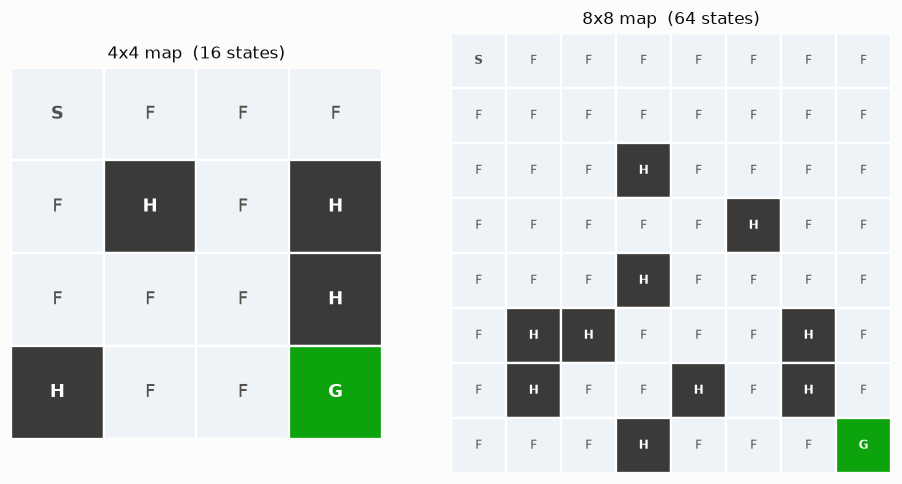

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, m in zip(axes, MAPS):
    env = fl.make_env(m)
    plot.draw_map(ax, fl.tiles(env), fl.grid_shape(env), title=f"{m} map  ({env.observation_space.n} states)")
plt.tight_layout(); plot.save_fig(fig, "01_maps"); plt.show()

## Rewards

After every step the agent gets a **reward**: a number that says how good that step was.
By default, FrozenLake gives 1 for reaching the goal and 0 for everything else. That has two problems:
falling in a hole scores the same as wandering around, and a slow route scores the same as a fast one.

So we **changed the rewards**:

In [3]:
pd.DataFrame({"event": ["reach the goal G", "fall into a hole H", "any other step"],
              "reward": [CONFIG["rewards"]["goal"], CONFIG["rewards"]["hole"], CONFIG["rewards"]["step"]]})

,event,reward
0,reach the goal G,1.00
1,fall into a hole H,-1.00
2,any other step,-0.01


- **+1 for reaching the goal.** This is what the agent wants.
- **−1 for falling in a hole.** Failing is now clearly bad.
- **−0.01 for every other step.** A small cost per step, so a shorter route earns more in total.
  For example, the shortest route on the 4x4 map is 6 steps. Its total reward is 5 × (−0.01) + 1 = **0.95**.
  A 10-step route only gets 0.91.

These numbers are set in one place: `CONFIG["rewards"]` in `frozenlake_rl/config.py`.
A small **wrapper** sits around the gymnasium environment and swaps the old reward for the new one.
This means Q-learning and SARSA both see exactly the same rewards.

Below is one short episode played by hand on the 4x4 map. It shows the old and the new reward for each step:

In [4]:
env = fl.make_env("4x4")
s, _ = env.reset(seed=0)
rows = []
for a in [1, 1, 2, 1, 2, 2]:        # down, down, right, down, right, right
    s2, r, terminated, truncated, info = env.step(a)
    rows.append({"from state": s, "action": fl.ACTION_NAMES[a], "to state": s2,
                 "square": fl.tiles(env)[s2], "original reward": info["original_reward"],
                 "shaped reward": r, "episode over?": terminated or truncated})
    s = s2
episode = pd.DataFrame(rows)
display(episode)
print("Total shaped reward (the 'return'):", round(episode["shaped reward"].sum(), 2))

,from state,action,to state,square,original reward,shaped reward,episode over?
0,0,down,4,F,0,-0.01,False
1,4,down,8,F,0,-0.01,False
2,8,right,9,F,0,-0.01,False
3,9,down,13,F,0,-0.01,False
4,13,right,14,F,0,-0.01,False
5,14,right,15,G,1,1.00,True


Total shaped reward (the 'return'): 0.95


## Value Iteration gets the same rewards

Value Iteration (notebook 02) does not play episodes. Instead it reads the **rules of the game** directly:
for every square and action, where the agent ends up and what reward it gets.
Gymnasium stores these rules in `env.unwrapped.P`, but that table has the **old** rewards (1 and 0).
If Value Iteration used it, it would be solving a different problem from the other two methods.

So `build_model()` copies the rules and works out every reward with the **same function** the wrapper uses.
The cell below checks every (square, action) pair on both maps. The test file `tests/test_basic.py` checks the same thing.

In [5]:
for m in MAPS:
    env = fl.make_env(m)
    P = fl.build_model(env)
    checked = mismatches = 0
    for s in range(env.observation_space.n):
        if s in fl.terminal_states(env):
            continue
        for a in range(env.action_space.n):
            env.reset(); env.unwrapped.s = s
            s2, r, *_ = env.step(a)
            (_, s2_model, r_model, _), = P[s][a]
            checked += 1
            mismatches += (s2, r) != (s2_model, r_model)
    print(f"{m}: checked {checked} (state, action) pairs, mismatches = {mismatches}")

4x4: checked 44 (state, action) pairs, mismatches = 0
8x8: checked 212 (state, action) pairs, mismatches = 0


## Why is the ice not slippery? (`is_slippery=False`)

In normal FrozenLake the ice is **slippery**: the agent only moves the way it chose 1/3 of the time,
and slides sideways the rest of the time. We turned this off, so every move goes exactly where the agent chose.

**Why we did this**
- The results are easy to check. There is one clear shortest route, and we can see whether each method finds it.
- Route length has a clear meaning: "the agent reached the goal in 6 steps" is an exact fact.
- Testing is quick. A policy does exactly the same thing every time, so one test episode tells us everything.

**What we lose**
- Real robots and games are rarely perfect. With no slipping, we can't see how the methods deal with
  uncertain moves, for example whether an agent learns to keep away from holes in case it slips.
- Some differences between Q-learning and SARSA only really show up when moves are risky (see notebook 05).

**Trying the slippery version:** set `SLIPPERY = True` in `frozenlake_rl/config.py` and run `python run_all.py`.
The training budgets and the number of test episodes change automatically, because slippery ice needs more of both.

## Other settings

- **Step limit:** an episode stops after a maximum number of steps, so an agent that walks in circles can't go on
  forever. Running out of steps counts as a failure (a "timeout").
- **Discount factor, gamma = 0.99** (the same for all methods): how much a reward in the future is worth compared
  with getting it now. 0.99 means "almost as much", so the agent plans far ahead.

In [6]:
pd.DataFrame({m: {"grid": "x".join(map(str, fl.grid_shape(fl.make_env(m)))),
                  "states": fl.make_env(m).observation_space.n,
                  "step limit": CONFIG["maps"][m]["max_steps"]} for m in MAPS}).T

,grid,states,step limit
4x4,4x4,16,100
8x8,8x8,64,200
